# EGFR Bioactivity Prediction with Machine Learning

**End-to-end cheminformatics project** using ChEMBL, RDKit, pandas, and scikit-learn.

## Objective
Retrieve EGFR inhibitor IC50 measurements from ChEMBL, clean and standardize the data, calculate molecular descriptors and Morgan fingerprints, then train and evaluate Random Forest regression models to predict pIC50.

> This is an educational research workflow, not a tool for clinical or therapeutic decision-making.

## Reproducibility notes
- Target: EGFR (`CHEMBL203`)
- Endpoint: exact IC50 measurements (`standard_type = IC50`, `standard_relation = =`)
- Activity unit: nM, converted to pIC50 using `9 - log10(IC50_nM)`
- Evaluation: held-out random test set; this is a baseline, not a prospective validation.

## 1. Install dependencies
Run this cell in Google Colab or a compatible Jupyter environment.

In [1]:
%pip -q install chembl_webresource_client rdkit scikit-learn pandas numpy matplotlib seaborn

## 2. Imports and configuration

In [2]:

import warnings
warnings.filterwarnings("ignore")

import json
import time
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests

from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

from rdkit import Chem, DataStructs
from rdkit.Chem import Descriptors, rdMolDescriptors
from rdkit.Chem.rdFingerprintGenerator import GetMorganGenerator

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

RANDOM_STATE = 42
TARGET_CHEMBL_ID = "CHEMBL203"
TEST_SIZE = 0.20

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

print("Core libraries imported successfully.")
print("Run started (UTC):", datetime.now(timezone.utc).isoformat())


Core libraries imported successfully.
Run started (UTC): 2026-11-26T10:58:31.728703+00:00


## 3. Retrieve bioactivity data from ChEMBL

We request exact IC50 measurements for EGFR. ChEMBL is a curated bioactivity database; records can still vary in assay conditions and quality, so this dataset should be treated as heterogeneous experimental data.

In [26]:

# Retrieve EGFR bioactivity data from the downloaded ChEMBL JSON file

import json
from pathlib import Path
import pandas as pd
import numpy as np

# Locate the previously uploaded JSON file
json_files = list(Path("/content").glob("*egfr*ic50*.json*"))

if not json_files:
    raise FileNotFoundError(
        "EGFR IC50 JSON file not found. Upload egfr_ic50.json "
        "using the Colab Files panel."
    )

json_path = json_files[0]
print(f"Loading ChEMBL data from: {json_path.name}")

# Load JSON data
with open(json_path, "r", encoding="utf-8") as file:
    json_data = json.load(file)

# Support common ChEMBL JSON response formats
if isinstance(json_data, list):
    all_records = json_data
elif isinstance(json_data, dict):
    for key in ["activities", "data", "results"]:
        if isinstance(json_data.get(key), list):
            all_records = json_data[key]
            break
    else:
        raise ValueError(
            "Could not find activity records in the JSON file."
        )
else:
    raise ValueError("Unexpected JSON data format.")

raw_df = pd.DataFrame(all_records)

if raw_df.empty:
    raise ValueError("No EGFR IC50 records found in the JSON file.")

# Ensure all downstream-required columns exist
required_columns = [
    "activity_id",
    "molecule_chembl_id",
    "canonical_smiles",
    "standard_value",
    "standard_units",
    "standard_type",
    "standard_relation",
    "assay_chembl_id",
    "document_chembl_id"
]

for column in required_columns:
    if column not in raw_df.columns:
        raw_df[column] = np.nan

raw_df = raw_df[required_columns]

print("\nChEMBL JSON data loaded successfully!")
print(f"Total activity records: {len(raw_df):,}")
print(f"Unique compounds: {raw_df['molecule_chembl_id'].nunique():,}")
print(
    f"Records with SMILES: "
    f"{raw_df['canonical_smiles'].notna().sum():,}"
)

display(raw_df.head())


Loading ChEMBL data from: egfr_ic50.json..json

ChEMBL JSON data loaded successfully!
Total activity records: 1,000
Unique compounds: 777
Records with SMILES: 1,000


,activity_id,molecule_chembl_id,canonical_smiles,standard_value,standard_units,standard_type,standard_relation,assay_chembl_id,document_chembl_id
0,32260,CHEMBL68920,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,41.0,nM,IC50,=,CHEMBL674637,CHEMBL1134862
1,32263,CHEMBL68920,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,300.0,nM,IC50,=,CHEMBL621151,CHEMBL1134862
2,32265,CHEMBL68920,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,7820.0,nM,IC50,=,CHEMBL615325,CHEMBL1134862
3,32267,CHEMBL69960,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...,170.0,nM,IC50,=,CHEMBL674637,CHEMBL1134862
4,32270,CHEMBL69960,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...,40.0,nM,IC50,=,CHEMBL621151,CHEMBL1134862


In [27]:
import json
from pathlib import Path

files_found = list(Path("/content").glob("*egfr*"))

print("Matching files:")
for f in files_found:
    print(f.name)

for f in files_found:
    if f.is_file() and f.suffix == ".json":
        with open(f, "r", encoding="utf-8") as file:
            data = json.load(file)

        print("\nFile:", f.name)
        print("Data type:", type(data))
        if isinstance(data, dict):
            print("Top-level keys:", list(data.keys()))
        elif isinstance(data, list):
            print("Number of records:", len(data))
            print("First record:", data[0] if data else "Empty")

Matching files:
egfr_ic50.json..json

File: egfr_ic50.json..json
Data type: <class 'dict'>
Top-level keys: ['activities', 'page_meta']


In [28]:
activities = data["activities"]

print("Number of activity records:", len(activities))
print("First activity record:")
print(activities[0])

Number of activity records: 1000
First activity record:
{'action_type': None, 'activity_comment': None, 'activity_id': 32260, 'activity_properties': [], 'assay_chembl_id': 'CHEMBL674637', 'assay_description': 'Inhibitory activity towards tyrosine phosphorylation for the epidermal growth factor-receptor kinase', 'assay_type': 'B', 'assay_variant_accession': None, 'assay_variant_mutation': None, 'bao_endpoint': 'BAO_0000190', 'bao_format': 'BAO_0000357', 'bao_label': 'single protein format', 'canonical_smiles': 'Cc1cc(C)c(/C=C2\\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)c32)[nH]1', 'data_validity_comment': None, 'data_validity_description': None, 'document_chembl_id': 'CHEMBL1134862', 'document_journal': 'Bioorg Med Chem Lett', 'document_year': 2002, 'ligand_efficiency': {'bei': '19.25', 'le': '0.37', 'lle': '2.94', 'sei': '8.93'}, 'modality': None, 'molecule_chembl_id': 'CHEMBL68920', 'molecule_pref_name': None, 'parent_molecule_chembl_id': 'CHEMBL68920', 'pchembl_value': '7.39', 'potential_duplica

In [29]:
raw_df = pd.DataFrame(activities)

print("Dataset shape:", raw_df.shape)
print("\nAvailable columns:")
print(raw_df.columns.tolist())

display(raw_df.head())

Dataset shape: (1000, 47)

Available columns:
['action_type', 'activity_comment', 'activity_id', 'activity_properties', 'assay_chembl_id', 'assay_description', 'assay_type', 'assay_variant_accession', 'assay_variant_mutation', 'bao_endpoint', 'bao_format', 'bao_label', 'canonical_smiles', 'data_validity_comment', 'data_validity_description', 'document_chembl_id', 'document_journal', 'document_year', 'ligand_efficiency', 'modality', 'molecule_chembl_id', 'molecule_pref_name', 'parent_molecule_chembl_id', 'pchembl_value', 'potential_duplicate', 'qudt_units', 'record_id', 'relation', 'src_id', 'standard_flag', 'standard_relation', 'standard_text_value', 'standard_type', 'standard_units', 'standard_upper_value', 'standard_value', 'target_chembl_id', 'target_organism', 'target_pref_name', 'target_tax_id', 'text_value', 'toid', 'type', 'units', 'uo_units', 'upper_value', 'value']


,action_type,activity_comment,activity_id,activity_properties,assay_chembl_id,assay_description,assay_type,assay_variant_accession,assay_variant_mutation,bao_endpoint,bao_format,bao_label,canonical_smiles,data_validity_comment,data_validity_description,document_chembl_id,document_journal,document_year,ligand_efficiency,modality,molecule_chembl_id,molecule_pref_name,parent_molecule_chembl_id,pchembl_value,potential_duplicate,qudt_units,record_id,relation,src_id,standard_flag,standard_relation,standard_text_value,standard_type,standard_units,standard_upper_value,standard_value,target_chembl_id,target_organism,target_pref_name,target_tax_id,text_value,toid,type,units,uo_units,upper_value,value
0,None,None,32260,[],CHEMBL674637,Inhibitory activity towards tyrosine phosphory...,B,None,None,BAO_0000190,BAO_0000357,single protein format,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,None,None,CHEMBL1134862,Bioorg Med Chem Lett,2002,"{'bei': '19.25', 'le': '0.37', 'lle': '2.94', ...",None,CHEMBL68920,None,CHEMBL68920,7.39,0,http://www.openphacts.org/units/Nanomolar,119482,=,1,1,=,None,IC50,nM,None,41.0,CHEMBL203,Homo sapiens,Epidermal growth factor receptor,9606,None,None,IC50,uM,UO_0000065,None,0.041
1,None,None,32263,[],CHEMBL621151,Inhibition of autophosphorylation of human epi...,F,None,None,BAO_0000190,BAO_0000219,cell-based format,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,None,None,CHEMBL1134862,Bioorg Med Chem Lett,2002,None,None,CHEMBL68920,None,CHEMBL68920,6.52,0,http://www.openphacts.org/units/Nanomolar,119482,=,1,1,=,None,IC50,nM,None,300.0,CHEMBL203,Homo sapiens,Epidermal growth factor receptor,9606,None,None,IC50,uM,UO_0000065,None,0.3
2,None,None,32265,[],CHEMBL615325,Inhibition of ligand-induced proliferation in ...,F,None,None,BAO_0000190,BAO_0000219,cell-based format,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,None,None,CHEMBL1134862,Bioorg Med Chem Lett,2002,None,None,CHEMBL68920,None,CHEMBL68920,5.11,0,http://www.openphacts.org/units/Nanomolar,119482,=,1,1,=,None,IC50,nM,None,7820.0,CHEMBL203,Homo sapiens,Epidermal growth factor receptor,9606,None,None,IC50,uM,UO_0000065,None,7.82
3,None,None,32267,[],CHEMBL674637,Inhibitory activity towards tyrosine phosphory...,B,None,None,BAO_0000190,BAO_0000357,single protein format,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...,None,None,CHEMBL1134862,Bioorg Med Chem Lett,2002,"{'bei': '14.02', 'le': '0.27', 'lle': '3.16', ...",None,CHEMBL69960,None,CHEMBL69960,6.77,0,http://www.openphacts.org/units/Nanomolar,119494,=,1,1,=,None,IC50,nM,None,170.0,CHEMBL203,Homo sapiens,Epidermal growth factor receptor,9606,None,None,IC50,uM,UO_0000065,None,0.17
4,None,None,32270,[],CHEMBL621151,Inhibition of autophosphorylation of human epi...,F,None,None,BAO_0000190,BAO_0000219,cell-based format,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...,None,None,CHEMBL1134862,Bioorg Med Chem Lett,2002,None,None,CHEMBL69960,None,CHEMBL69960,7.40,0,http://www.openphacts.org/units/Nanomolar,119494,=,1,1,=,None,IC50,nM,None,40.0,CHEMBL203,Homo sapiens,Epidermal growth factor receptor,9606,None,None,IC50,uM,UO_0000065,None,0.04


In [30]:
required = [
    "activity_id",
    "molecule_chembl_id",
    "canonical_smiles",
    "standard_value",
    "standard_units",
    "standard_type",
    "standard_relation",
    "assay_chembl_id",
    "document_chembl_id"
]

for col in required:
    print(f"{col}: {'FOUND' if col in raw_df.columns else 'MISSING'}")

activity_id: FOUND
molecule_chembl_id: FOUND
canonical_smiles: FOUND
standard_value: FOUND
standard_units: FOUND
standard_type: FOUND
standard_relation: FOUND
assay_chembl_id: FOUND
document_chembl_id: FOUND


In [7]:

import requests

# Test direct connection from Google Colab to ChEMBL
test_url = "https://www.ebi.ac.uk/chembl/api/data/activity.json"

test_params = {
    "target_chembl_id": "CHEMBL203",
    "standard_type": "IC50",
    "standard_relation": "=",
    "limit": 1
}

print("Testing ChEMBL connection from Google Colab...")

try:
    response = requests.get(
        test_url,
        params=test_params,
        timeout=30
    )

    response.raise_for_status()

    data = response.json()

    print("\nCOLAB CONNECTION SUCCESSFUL!")
    print("Total matching records:", data["page_meta"]["total_count"])
    print(
        "Sample molecule:",
        data["activities"][0]["molecule_chembl_id"]
    )
    print(
        "Sample IC50:",
        data["activities"][0]["standard_value"],
        data["activities"][0]["standard_units"]
    )

except requests.exceptions.RequestException as error:
    print("\nCOLAB CONNECTION FAILED")
    print("Network error:", str(error))

except (KeyError, IndexError) as error:
    print("\nDATA RESPONSE ERROR")
    print("Details:", str(error))


Testing ChEMBL connection from Google Colab...

COLAB CONNECTION FAILED
Network error: ('Connection aborted.', ConnectionResetError(104, 'Connection reset by peer'))


## 4. Clean data and calculate pIC50

Keep positive, numeric IC50 values reported in nM and exact (`=`) measurements. Remove rows without usable SMILES. Duplicate handling is performed at the compound level after sorting, and conflicting repeated measurements are summarized by their median pIC50 rather than arbitrarily selecting one record.

In [15]:

# ============================================================
# 4. CLEAN DATA AND CALCULATE pIC50
# ============================================================

required = [
    "molecule_chembl_id",
    "canonical_smiles",
    "standard_value",
    "standard_units",
    "standard_type",
    "standard_relation"
]

missing = [col for col in required if col not in raw_df.columns]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

# Create a working copy
df = raw_df.copy()

# Convert IC50 values to numeric
df["standard_value"] = pd.to_numeric(
    df["standard_value"], errors="coerce"
)

# Remove missing values
df = df.dropna(subset=required)

# Filter valid exact IC50 measurements in nM
df = df[
    (df["standard_type"] == "IC50") &
    (df["standard_relation"] == "=") &
    (df["standard_units"].str.lower() == "nm") &
    (df["standard_value"] > 0)
].copy()

print("Records after filtering:", len(df))

# Convert SMILES into RDKit molecules
df["mol"] = df["canonical_smiles"].apply(
    Chem.MolFromSmiles
)

# Remove invalid molecular structures
df = df[df["mol"].notna()].copy()

# Calculate pIC50
df["pIC50"] = 9 - np.log10(df["standard_value"])

# Standardize molecular structures
df["canonical_smiles"] = df["mol"].apply(
    Chem.MolToSmiles
)

# Aggregate repeated measurements by compound and structure
clean_df = (
    df.groupby(
        ["molecule_chembl_id", "canonical_smiles"],
        as_index=False
    )
    .agg(
        pIC50=("pIC50", "median"),
        n_measurements=("pIC50", "size")
    )
)

# Remove duplicate standardized structures
clean_df = (
    clean_df.drop_duplicates(subset=["canonical_smiles"])
    .reset_index(drop=True)
)

# Final output
print("\nDATA CLEANING COMPLETED")
print("Original records:", len(raw_df))
print("Filtered records:", len(df))
print("Unique usable compounds:", len(clean_df))

print("\npIC50 statistical summary:")
print(clean_df["pIC50"].describe())

display(clean_df.head())


Records after filtering: 1000

DATA CLEANING COMPLETED
Original records: 1000
Filtered records: 1000
Unique usable compounds: 777

pIC50 statistical summary:
count    777.000000
mean       6.184710
std        1.516302
min        2.187087
25%        5.124977
50%        6.173925
75%        7.193820
max       11.221849
Name: pIC50, dtype: float64


,molecule_chembl_id,canonical_smiles,pIC50,n_measurements
0,CHEMBL10,C[S+]([O-])c1ccc(-c2nc(-c3ccc(F)cc3)c(-c3ccncc...,4.017729,1
1,CHEMBL100714,COc1ccc(Nc2ncnc3cc(OC)c(OC)cc23)cc1OC,5.552842,1
2,CHEMBL1009,N[C@@H](Cc1ccc(O)c(O)c1)C(=O)O,3.045757,1
3,CHEMBL101581,COc1cc2nccc(Oc3cccc(Br)c3)c2cc1OC,5.602060,1
4,CHEMBL104153,COc1ccc(Nc2ncc3cc(-c4c(Cl)cccc4Cl)c(=O)n(C)c3n...,6.657577,1


In [14]:

# ============================================================
# 4. DATASET QUALITY ASSESSMENT
# EGFR Bioactivity Prediction Project
# ============================================================

print("=" * 60)
print("EGFR BIOACTIVITY DATASET QUALITY REPORT")
print("=" * 60)


# 1. Dataset dimensions
print("\n1. DATASET DIMENSIONS")

print("Dataset shape:", raw_df.shape)
print("Total records:", len(raw_df))
print("Total columns:", len(raw_df.columns))


# 2. Missing values
print("\n2. MISSING VALUES")

missing = raw_df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if len(missing) > 0:
    display(missing.to_frame(name="Missing Count"))
else:
    print("No missing values found.")


# 3. Duplicate records
print("\n3. DUPLICATE RECORDS")

# Avoid columns containing lists or dictionaries
duplicate_columns = [
    "molecule_chembl_id",
    "assay_chembl_id",
    "standard_type",
    "standard_relation",
    "standard_value",
    "standard_units"
]

duplicate_columns = [
    col for col in duplicate_columns
    if col in raw_df.columns
]

if duplicate_columns:
    duplicate_count = raw_df.duplicated(
        subset=duplicate_columns
    ).sum()

    print("Duplicate records:", duplicate_count)
else:
    print("No suitable columns available for duplicate checking.")


# 4. Required columns
print("\n4. REQUIRED COLUMN AVAILABILITY")

required_columns = [
    "molecule_chembl_id",
    "canonical_smiles",
    "standard_value",
    "standard_units",
    "standard_type",
    "standard_relation"
]

for col in required_columns:
    status = "AVAILABLE" if col in raw_df.columns else "MISSING"
    print(f"{col}: {status}")


# 5. IC50 distribution
print("\n5. IC50 VALUE DISTRIBUTION")

if "standard_value" in raw_df.columns:

    ic50_values = pd.to_numeric(
        raw_df["standard_value"],
        errors="coerce"
    )

    ic50_values = ic50_values[
        ic50_values.notna() & (ic50_values > 0)
    ]

    if len(ic50_values) > 0:
        print("Valid positive IC50 measurements:")
        print(ic50_values.describe())
    else:
        print("No valid positive IC50 values found.")

else:
    print("standard_value column unavailable.")


# 6. SMILES availability
print("\n6. SMILES AVAILABILITY")

if "canonical_smiles" in raw_df.columns:

    valid_smiles = raw_df["canonical_smiles"].notna().sum()

    print("Available SMILES:", valid_smiles)
    print("Missing SMILES:", raw_df["canonical_smiles"].isna().sum())

    print(
        "Unique SMILES:",
        raw_df["canonical_smiles"].nunique()
    )

else:
    print("canonical_smiles column unavailable.")


# 7. Bioactivity measurement distribution
print("\n7. BIOACTIVITY MEASUREMENT DISTRIBUTION")

for col in ["standard_type", "standard_units", "standard_relation"]:

    if col in raw_df.columns:
        print(f"\n{col}:")
        print(raw_df[col].value_counts(dropna=False).head(10))


# 8. Dataset preview
print("\n8. DATASET PREVIEW")

display(raw_df.head())


# 9. Final report
print("\n" + "=" * 60)
print("DATASET QUALITY ASSESSMENT COMPLETED")
print("=" * 60)

print("Records available:", len(raw_df))
print("Unique compounds:",
      raw_df["molecule_chembl_id"].nunique()
      if "molecule_chembl_id" in raw_df.columns
      else "Unavailable")

print("Dataset columns:", len(raw_df.columns))


EGFR BIOACTIVITY DATASET QUALITY REPORT

1. DATASET DIMENSIONS
Dataset shape: (1000, 47)
Total records: 1000
Total columns: 47

2. MISSING VALUES


,Missing Count
action_type,1000
activity_comment,1000
assay_variant_accession,1000
assay_variant_mutation,1000
modality,1000
toid,1000
standard_text_value,1000
standard_upper_value,1000
upper_value,1000
text_value,1000



3. DUPLICATE RECORDS
Duplicate records: 0

4. REQUIRED COLUMN AVAILABILITY
molecule_chembl_id: AVAILABLE
canonical_smiles: AVAILABLE
standard_value: AVAILABLE
standard_units: AVAILABLE
standard_type: AVAILABLE
standard_relation: AVAILABLE

5. IC50 VALUE DISTRIBUTION
Valid positive IC50 measurements:
count    1.000000e+03
mean     4.512848e+04
std      2.786738e+05
min      6.000000e-03
25%      3.575000e+01
50%      4.300000e+02
75%      5.227017e+03
max      6.500000e+06
Name: standard_value, dtype: float64

6. SMILES AVAILABILITY
Available SMILES: 1000
Missing SMILES: 0
Unique SMILES: 777

7. BIOACTIVITY MEASUREMENT DISTRIBUTION

standard_type:
standard_type
IC50    1000
Name: count, dtype: int64

standard_units:
standard_units
nM    1000
Name: count, dtype: int64

standard_relation:
standard_relation
=    1000
Name: count, dtype: int64

8. DATASET PREVIEW


,action_type,activity_comment,activity_id,activity_properties,assay_chembl_id,assay_description,assay_type,assay_variant_accession,assay_variant_mutation,bao_endpoint,bao_format,bao_label,canonical_smiles,data_validity_comment,data_validity_description,document_chembl_id,document_journal,document_year,ligand_efficiency,modality,molecule_chembl_id,molecule_pref_name,parent_molecule_chembl_id,pchembl_value,potential_duplicate,qudt_units,record_id,relation,src_id,standard_flag,standard_relation,standard_text_value,standard_type,standard_units,standard_upper_value,standard_value,target_chembl_id,target_organism,target_pref_name,target_tax_id,text_value,toid,type,units,uo_units,upper_value,value
0,None,None,32260,[],CHEMBL674637,Inhibitory activity towards tyrosine phosphory...,B,None,None,BAO_0000190,BAO_0000357,single protein format,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,None,None,CHEMBL1134862,Bioorg Med Chem Lett,2002,"{'bei': '19.25', 'le': '0.37', 'lle': '2.94', ...",None,CHEMBL68920,None,CHEMBL68920,7.39,0,http://www.openphacts.org/units/Nanomolar,119482,=,1,1,=,None,IC50,nM,None,41.0,CHEMBL203,Homo sapiens,Epidermal growth factor receptor,9606,None,None,IC50,uM,UO_0000065,None,0.041
1,None,None,32263,[],CHEMBL621151,Inhibition of autophosphorylation of human epi...,F,None,None,BAO_0000190,BAO_0000219,cell-based format,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,None,None,CHEMBL1134862,Bioorg Med Chem Lett,2002,None,None,CHEMBL68920,None,CHEMBL68920,6.52,0,http://www.openphacts.org/units/Nanomolar,119482,=,1,1,=,None,IC50,nM,None,300.0,CHEMBL203,Homo sapiens,Epidermal growth factor receptor,9606,None,None,IC50,uM,UO_0000065,None,0.3
2,None,None,32265,[],CHEMBL615325,Inhibition of ligand-induced proliferation in ...,F,None,None,BAO_0000190,BAO_0000219,cell-based format,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,None,None,CHEMBL1134862,Bioorg Med Chem Lett,2002,None,None,CHEMBL68920,None,CHEMBL68920,5.11,0,http://www.openphacts.org/units/Nanomolar,119482,=,1,1,=,None,IC50,nM,None,7820.0,CHEMBL203,Homo sapiens,Epidermal growth factor receptor,9606,None,None,IC50,uM,UO_0000065,None,7.82
3,None,None,32267,[],CHEMBL674637,Inhibitory activity towards tyrosine phosphory...,B,None,None,BAO_0000190,BAO_0000357,single protein format,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...,None,None,CHEMBL1134862,Bioorg Med Chem Lett,2002,"{'bei': '14.02', 'le': '0.27', 'lle': '3.16', ...",None,CHEMBL69960,None,CHEMBL69960,6.77,0,http://www.openphacts.org/units/Nanomolar,119494,=,1,1,=,None,IC50,nM,None,170.0,CHEMBL203,Homo sapiens,Epidermal growth factor receptor,9606,None,None,IC50,uM,UO_0000065,None,0.17
4,None,None,32270,[],CHEMBL621151,Inhibition of autophosphorylation of human epi...,F,None,None,BAO_0000190,BAO_0000219,cell-based format,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...,None,None,CHEMBL1134862,Bioorg Med Chem Lett,2002,None,None,CHEMBL69960,None,CHEMBL69960,7.40,0,http://www.openphacts.org/units/Nanomolar,119494,=,1,1,=,None,IC50,nM,None,40.0,CHEMBL203,Homo sapiens,Epidermal growth factor receptor,9606,None,None,IC50,uM,UO_0000065,None,0.04



DATASET QUALITY ASSESSMENT COMPLETED
Records available: 1000
Unique compounds: 777
Dataset columns: 47


In [31]:
required = ["molecule_chembl_id", "canonical_smiles", "standard_value", "standard_units"]
missing = [c for c in required if c not in raw_df.columns]
if missing:
    raise ValueError(f"ChEMBL response is missing expected columns: {missing}")

df = raw_df.copy()
df["standard_value"] = pd.to_numeric(df["standard_value"], errors="coerce")
df = df.dropna(subset=required)
df = df[(df["standard_units"].str.lower() == "nm") & (df["standard_value"] > 0)]

# Keep only rows with valid RDKit-parsable SMILES.
df["mol"] = df["canonical_smiles"].apply(Chem.MolFromSmiles)
df = df[df["mol"].notna()].copy()

# pIC50 = -log10(IC50 in molar) = 9 - log10(IC50 in nM)
df["pIC50"] = 9 - np.log10(df["standard_value"])

# Canonicalize structures so equivalent SMILES map to the same structure.
df["canonical_smiles"] = df["mol"].apply(Chem.MolToSmiles)

# Aggregate repeated measurements for each standardized structure.
clean_df = (
    df.groupby(["molecule_chembl_id", "canonical_smiles"], as_index=False)
      .agg(pIC50=("pIC50", "median"),
           n_measurements=("pIC50", "size"))
)

clean_df = clean_df.drop_duplicates(subset=["canonical_smiles"]).reset_index(drop=True)

print(f"Usable compounds: {len(clean_df):,}")
print(clean_df["pIC50"].describe())
display(clean_df.head())

Usable compounds: 777
count    777.000000
mean       6.184710
std        1.516302
min        2.187087
25%        5.124977
50%        6.173925
75%        7.193820
max       11.221849
Name: pIC50, dtype: float64


,molecule_chembl_id,canonical_smiles,pIC50,n_measurements
0,CHEMBL10,C[S+]([O-])c1ccc(-c2nc(-c3ccc(F)cc3)c(-c3ccncc...,4.017729,1
1,CHEMBL100714,COc1ccc(Nc2ncnc3cc(OC)c(OC)cc23)cc1OC,5.552842,1
2,CHEMBL1009,N[C@@H](Cc1ccc(O)c(O)c1)C(=O)O,3.045757,1
3,CHEMBL101581,COc1cc2nccc(Oc3cccc(Br)c3)c2cc1OC,5.602060,1
4,CHEMBL104153,COc1ccc(Nc2ncc3cc(-c4c(Cl)cccc4Cl)c(=O)n(C)c3n...,6.657577,1


### Data quality checks

A model trained on very few compounds may be unstable. The following check makes the dataset size visible before training.

In [ ]:
if len(clean_df) < 30:
    print("WARNING: Fewer than 30 unique compounds. Treat model metrics as highly preliminary.")
elif len(clean_df) < 100:
    print("Note: Dataset is modest in size; performance estimates may have high uncertainty.")
else:
    print("Dataset contains at least 100 unique compounds.")

plt.figure(figsize=(7, 4))
sns.histplot(clean_df["pIC50"], bins=30, kde=True)
plt.title("Distribution of EGFR pIC50 values")
plt.xlabel("pIC50")
plt.tight_layout()
plt.show()

## 5. Calculate Molecular Descriptors

In this section, RDKit is used to calculate molecular descriptors for the cleaned EGFR compound dataset.

The following molecular properties are calculated:

- Molecular Weight (MW)
- Lipophilicity (LogP)
- Number of Hydrogen Bond Donors
- Number of Hydrogen Bond Acceptors
- Topological Polar Surface Area (TPSA)
- Number of Rotatable Bonds
- Number of Aromatic Rings
- Fraction of sp3 Hybridized Carbon Atoms (FractionCSP3)

These descriptors represent the physicochemical and structural characteristics of the compounds and will be used as input features for developing the EGFR bioactivity prediction model.

**Dataset used:** 777 unique compounds.


In [32]:

# ============================================================
# 5. CALCULATE MOLECULAR DESCRIPTORS
# ============================================================

import numpy as np
import pandas as pd

from rdkit import Chem
from rdkit.Chem import Descriptors, Lipinski, rdMolDescriptors

# Work with cleaned dataset
descriptor_df = clean_df.copy()

# Convert SMILES to molecular structures
descriptor_df["mol"] = descriptor_df["canonical_smiles"].apply(
    Chem.MolFromSmiles
)

# Remove invalid molecules
descriptor_df = descriptor_df.dropna(subset=["mol"]).copy()

# Calculate molecular descriptors
descriptor_df["MW"] = descriptor_df["mol"].apply(
    Descriptors.MolWt
)

descriptor_df["LogP"] = descriptor_df["mol"].apply(
    Descriptors.MolLogP
)

descriptor_df["NumHDonors"] = descriptor_df["mol"].apply(
    Lipinski.NumHDonors
)

descriptor_df["NumHAcceptors"] = descriptor_df["mol"].apply(
    Lipinski.NumHAcceptors
)

descriptor_df["TPSA"] = descriptor_df["mol"].apply(
    Descriptors.TPSA
)

descriptor_df["NumRotatableBonds"] = descriptor_df["mol"].apply(
    Lipinski.NumRotatableBonds
)

descriptor_df["NumAromaticRings"] = descriptor_df["mol"].apply(
    Lipinski.NumAromaticRings
)

descriptor_df["FractionCSP3"] = descriptor_df["mol"].apply(
    Descriptors.FractionCSP3
)

# Display results
descriptor_columns = [
    "MW",
    "LogP",
    "NumHDonors",
    "NumHAcceptors",
    "TPSA",
    "NumRotatableBonds",
    "NumAromaticRings",
    "FractionCSP3"
]

print("MOLECULAR DESCRIPTOR CALCULATION COMPLETED")
print("Total compounds:", len(descriptor_df))

print("\nDescriptor summary:")
display(descriptor_df[descriptor_columns].describe())

print("\nDataset preview:")
display(
    descriptor_df[
        ["molecule_chembl_id", "canonical_smiles", "pIC50"]
        + descriptor_columns
    ].head()
)

print("\nDataset shape:", descriptor_df.shape)


MOLECULAR DESCRIPTOR CALCULATION COMPLETED
Total compounds: 777

Descriptor summary:


,MW,LogP,NumHDonors,NumHAcceptors,TPSA,NumRotatableBonds,NumAromaticRings,FractionCSP3
count,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000
mean,393.962345,3.841925,2.061776,5.290862,84.672329,5.204633,3.115830,0.173238
std,113.480252,1.481484,1.148192,1.480224,26.985279,3.013386,1.148495,0.125923
min,143.149000,-1.303840,0.000000,2.000000,20.310000,0.000000,0.000000,0.000000
25%,312.764000,2.864100,1.000000,4.000000,66.490000,3.000000,3.000000,0.066667
50%,390.846000,3.840120,2.000000,5.000000,81.320000,5.000000,3.000000,0.157895
75%,462.953000,4.696800,3.000000,6.000000,97.960000,7.000000,4.000000,0.272727
max,934.658000,9.499000,8.000000,12.000000,272.980000,15.000000,6.000000,0.533333



Dataset preview:


,molecule_chembl_id,canonical_smiles,pIC50,MW,LogP,NumHDonors,NumHAcceptors,TPSA,NumRotatableBonds,NumAromaticRings,FractionCSP3
0,CHEMBL10,C[S+]([O-])c1ccc(-c2nc(-c3ccc(F)cc3)c(-c3ccncc...,4.017729,377.444,4.6822,1,3,64.63,4,4,0.047619
1,CHEMBL100714,COc1ccc(Nc2ncnc3cc(OC)c(OC)cc23)cc1OC,5.552842,341.367,3.4078,1,7,74.73,6,3,0.222222
2,CHEMBL1009,N[C@@H](Cc1ccc(O)c(O)c1)C(=O)O,3.045757,197.190,0.0522,4,4,103.78,3,1,0.222222
3,CHEMBL101581,COc1cc2nccc(Oc3cccc(Br)c3)c2cc1OC,5.602060,360.207,4.8068,0,4,40.58,4,3,0.117647
4,CHEMBL104153,COc1ccc(Nc2ncc3cc(-c4c(Cl)cccc4Cl)c(=O)n(C)c3n...,6.657577,427.291,5.0545,1,5,69.04,4,4,0.095238



Dataset shape: (777, 13)


In [17]:
def calculate_descriptors(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    return {
        "MolWt": Descriptors.MolWt(mol),
        "LogP": Descriptors.MolLogP(mol),
        "TPSA": Descriptors.TPSA(mol),
        "HBD": Descriptors.NumHDonors(mol),
        "HBA": Descriptors.NumHAcceptors(mol),
        "RotatableBonds": Descriptors.NumRotatableBonds(mol),
        "AromaticRings": rdMolDescriptors.CalcNumAromaticRings(mol),
        "HeavyAtomCount": Descriptors.HeavyAtomCount(mol),
        "FractionCSP3": rdMolDescriptors.CalcFractionCSP3(mol),
    }

descriptor_rows = clean_df["canonical_smiles"].apply(calculate_descriptors)
valid_mask = descriptor_rows.notna()

model_df = clean_df.loc[valid_mask].reset_index(drop=True)
X_desc = pd.DataFrame(descriptor_rows[valid_mask].tolist())
y = model_df["pIC50"].astype(float)

print("Descriptor matrix:", X_desc.shape)
display(X_desc.head())

Descriptor matrix: (777, 9)


,MolWt,LogP,TPSA,HBD,HBA,RotatableBonds,AromaticRings,HeavyAtomCount,FractionCSP3
0,377.444,4.6822,64.63,1,3,4,4,27,0.047619
1,341.367,3.4078,74.73,1,7,6,3,25,0.222222
2,197.190,0.0522,103.78,4,4,3,1,14,0.222222
3,360.207,4.8068,40.58,0,4,4,3,22,0.117647
4,427.291,5.0545,69.04,1,5,4,4,29,0.095238


## 6. Train/test split and descriptor model

The test set is held out from model fitting. A random split is convenient for a first project, but close analogues can appear in both sets. For a stronger assessment, use a scaffold split in a later iteration.

In [33]:
results_dir = Path("results")
results_dir.mkdir(exist_ok=True)

if len(model_df) < 10:
    raise ValueError("Too few valid compounds for a meaningful train/test split.")

X_train, X_test, y_train, y_test = train_test_split(
    X_desc, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

descriptor_model = RandomForestRegressor(
    n_estimators=400,
    min_samples_leaf=2,
    max_features=0.8,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
descriptor_model.fit(X_train, y_train)
pred_desc = descriptor_model.predict(X_test)

def regression_metrics(y_true, y_pred, label):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return {"Model": label, "R2": r2, "RMSE": rmse, "MAE": mae}

results = [regression_metrics(y_test, pred_desc, "RDKit descriptors")]
pd.DataFrame(results)


,Model,R2,RMSE,MAE
0,RDKit descriptors,0.599324,0.979883,0.778938


## 7. Actual vs predicted activity

Points near the diagonal represent more accurate predictions. Interpret the metrics together with the plot and test-set size.

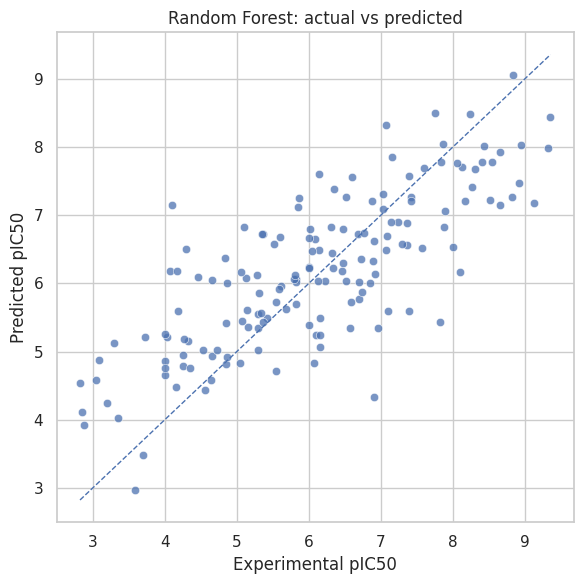

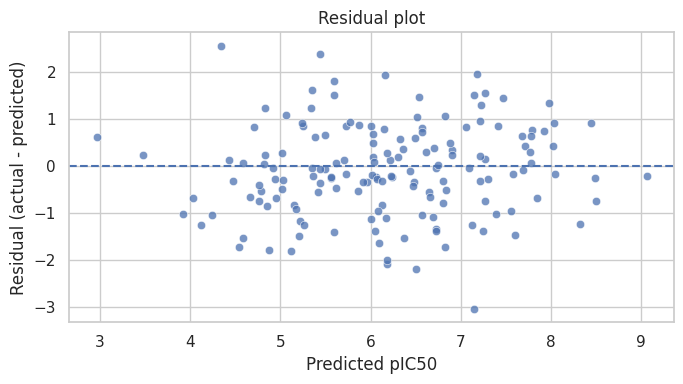

In [34]:
from pathlib import Path
results_dir = Path("results")
results_dir.mkdir(exist_ok=True)

plt.figure(figsize=(6, 6))
sns.scatterplot(x=y_test, y=pred_desc, alpha=0.75)
low = min(y_test.min(), pred_desc.min())
high = max(y_test.max(), pred_desc.max())
plt.plot([low, high], [low, high], "--", linewidth=1)
plt.xlabel("Experimental pIC50")
plt.ylabel("Predicted pIC50")
plt.title("Random Forest: actual vs predicted")
plt.tight_layout()
plt.savefig(results_dir / "actual_vs_predicted.png", dpi=160, bbox_inches="tight")
plt.show()

residuals = y_test.to_numpy() - pred_desc
plt.figure(figsize=(7, 4))
sns.scatterplot(x=pred_desc, y=residuals, alpha=0.75)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted pIC50")
plt.ylabel("Residual (actual - predicted)")
plt.title("Residual plot")
plt.tight_layout()
plt.savefig(results_dir / "residual_plot.png", dpi=160, bbox_inches="tight")
plt.show()


## 8. Feature importance

Random Forest impurity-based importance can be biased toward some feature types. Treat this plot as exploratory, not as evidence of biological causation.

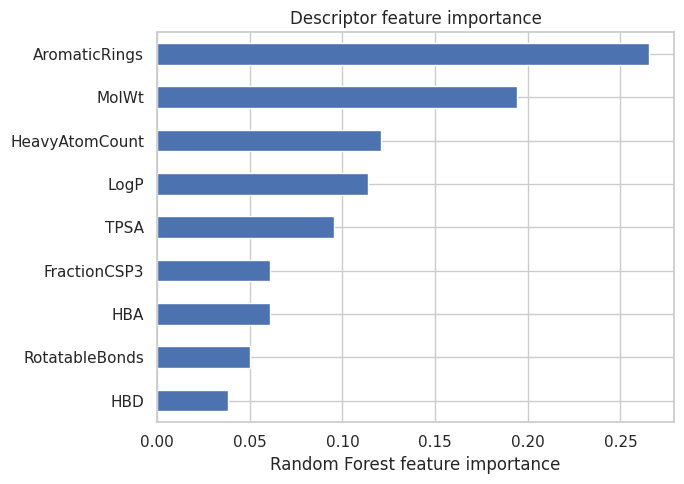

In [35]:
importance = pd.Series(
    descriptor_model.feature_importances_,
    index=X_desc.columns
).sort_values()

plt.figure(figsize=(7, 5))
importance.plot(kind="barh")
plt.xlabel("Random Forest feature importance")
plt.title("Descriptor feature importance")
plt.tight_layout()
plt.savefig(results_dir / "descriptor_importance.png", dpi=160, bbox_inches="tight")
plt.show()


## 9. Optional experiment: Morgan fingerprints

Morgan fingerprints encode local molecular environments and often capture structural information that a small set of physicochemical descriptors misses. This cell trains a second Random Forest model for comparison.

In [36]:
MORGAN_RADIUS = 2
MORGAN_BITS = 2048
fp_generator = GetMorganGenerator(radius=MORGAN_RADIUS, fpSize=MORGAN_BITS)

def smiles_to_fp(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    fp = fp_generator.GetFingerprint(mol)
    arr = np.zeros((MORGAN_BITS,), dtype=np.uint8)
    DataStructs.ConvertToNumpyArray(fp, arr)
    return arr

fps = model_df["canonical_smiles"].apply(smiles_to_fp)
fp_matrix = np.vstack(fps.to_list())

X_fp_train, X_fp_test, y_fp_train, y_fp_test = train_test_split(
    fp_matrix, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

fingerprint_model = RandomForestRegressor(
    n_estimators=400,
    min_samples_leaf=2,
    max_features="sqrt",
    random_state=RANDOM_STATE,
    n_jobs=-1
)
fingerprint_model.fit(X_fp_train, y_fp_train)
pred_fp = fingerprint_model.predict(X_fp_test)

results.append(regression_metrics(y_fp_test, pred_fp, "Morgan fingerprints"))
comparison = pd.DataFrame(results)
display(comparison)

,Model,R2,RMSE,MAE
0,RDKit descriptors,0.599324,0.979883,0.778938
1,Morgan fingerprints,0.759547,0.759089,0.576267


## 10. Results interpretation

Use the real metric values produced above. Do not copy example scores or claim that one model is better unless the held-out metrics support that conclusion.

Complete the short report below after running the notebook.

In [37]:
best_row = comparison.sort_values("RMSE").iloc[0]
print(f"Number of unique compounds: {len(model_df)}")
print(comparison.to_string(index=False))
print("\nLowest-RMSE baseline:", best_row["Model"])
print(f"R² = {best_row['R2']:.3f}; RMSE = {best_row['RMSE']:.3f}; MAE = {best_row['MAE']:.3f}")

Number of unique compounds: 777
              Model       R2     RMSE      MAE
  RDKit descriptors 0.599324 0.979883 0.778938
Morgan fingerprints 0.759547 0.759089 0.576267

Lowest-RMSE baseline: Morgan fingerprints
R² = 0.760; RMSE = 0.759; MAE = 0.576


### Suggested 3–4 sentence write-up

Replace the bracketed values with your actual results:

1. “We collected **[N]** unique EGFR compounds with exact IC50 measurements and converted the values to pIC50.”
2. “The RDKit descriptor Random Forest achieved **R² = [value]** and **RMSE = [value]** on the held-out test set.”
3. “The Morgan fingerprint model achieved **R² = [value]** and **RMSE = [value]**, suggesting [describe whether it improved over descriptors].”
4. “Performance is limited by assay heterogeneity, the size and composition of the dataset, and the random split; future work should use scaffold-based validation and carefully curated assay subsets.”

## 11. Limitations and next steps

- ChEMBL bioactivity values come from different assays and experimental conditions.
- This notebook filters to exact IC50 values in nM, but does not fully harmonize assay protocols.
- Aggregating repeated compound measurements by median reduces duplicates but can hide assay-dependent variation.
- A random split can overestimate generalization to genuinely new chemical scaffolds.
- Descriptor importance is not a causal explanation of molecular activity.
- Consider scaffold splitting, external validation, hyperparameter tuning, and assay-level curation before drawing strong conclusions.

## 12. Save outputs

The notebook can save the cleaned dataset and metrics for inclusion in the repository.

In [38]:
from pathlib import Path
results_dir = Path("results")
results_dir.mkdir(exist_ok=True)

clean_df.to_csv(results_dir / "egfr_cleaned_bioactivity.csv", index=False)
comparison.to_csv(results_dir / "model_comparison.csv", index=False)

# Save a compact run summary using the metrics calculated in this session.
summary = {
    "target": "EGFR (CHEMBL203)",
    "endpoint": "exact IC50 in nM",
    "n_unique_compounds": int(len(model_df)),
    "random_state": RANDOM_STATE,
    "test_size": TEST_SIZE,
    "best_model_by_rmse": str(best_row["Model"]),
    "best_model_r2": float(best_row["R2"]),
    "best_model_rmse": float(best_row["RMSE"]),
    "best_model_mae": float(best_row["MAE"]),
}
with open(results_dir / "run_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

print(f"Saved cleaned data, model comparison, and run summary in: {results_dir.resolve()}")


Saved cleaned data, model comparison, and run summary in: /content/results


In [24]:
import shutil

shutil.make_archive(
    "/content/EGFR_Results",
    "zip",
    "/content/results"
)

print("ZIP file created successfully!")

ZIP file created successfully!


In [25]:
from google.colab import files

files.download("/content/EGFR_Results.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## References

- ChEMBL: https://www.ebi.ac.uk/chembl/
- ChEMBL web services client: https://github.com/chembl/chembl_webresource_client
- RDKit documentation: https://www.rdkit.org/docs/
- scikit-learn RandomForestRegressor: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html

**Reproducibility:** Record the date you retrieved ChEMBL data and the package versions when you publish your final results.